In [180]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Offshore Wind Energy Yield & LCOE Model")
print("Stage 1: Wind Resource Data Preparation")


Offshore Wind Energy Yield & LCOE Model
Stage 1: Wind Resource Data Preparation


In [181]:
#Create a synthetic one-year offshore wind resource dataset
np.random.seed(42)
hours = 8760
timestamps = pd.date_range(
    start = "2025-01-01 00:00:00",
    periods = hours,
    freq = "h"
)

# Generate offshore wind speed
wind_speed = np.random.weibull(2.2, hours) * 8

wind_speed = np.clip(wind_speed, 0, 30).round(2)

#Generate wind direction
wind_direction = np.random.uniform(0, 360, hours).round(2)

#Genereta air-density variation
air_density = np.random.normal(1.225, 0.03, hours).round(2)

#Generate temperature
temperature = np.random.normal(10, 5, hours).round(2)

#Create the dataset
wind_data = pd.DataFrame({
    "timestamp": timestamps,
    "wind_speed_ms": wind_speed,
    "wind_direction_deg": wind_direction,
    "air density_kgm3": air_density,
    "temperature_c": temperature
})
wind_data.head()


,timestamp,wind_speed_ms,wind_direction_deg,air density_kgm3,temperature_c
0,2025-01-01 00:00:00,5.67,7.06,1.29,8.00
1,2025-01-01 01:00:00,13.20,241.69,1.26,15.32
2,2025-01-01 02:00:00,9.07,188.34,1.26,7.68
3,2025-01-01 03:00:00,7.68,323.51,1.22,17.85
4,2025-01-01 04:00:00,3.57,59.18,1.23,10.56


In [182]:
print("Number of observations:", len(wind_data))

Number of observations: 8760


In [183]:
wind_data.info()

wind_data.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   timestamp           8760 non-null   datetime64[us]
 1   wind_speed_ms       8760 non-null   float64       
 2   wind_direction_deg  8760 non-null   float64       
 3   air density_kgm3    8760 non-null   float64       
 4   temperature_c       8760 non-null   float64       
dtypes: datetime64[us](1), float64(4)
memory usage: 342.3 KB


timestamp             0
wind_speed_ms         0
wind_direction_deg    0
air density_kgm3      0
temperature_c         0
dtype: int64

In [184]:
wind_data.to_csv(
    "data/wind_resource.csv",
    index=False
)

print("Wind-resource dataset saved successfully.")

Wind-resource dataset saved successfully.


In [185]:
import os
print("I am standing right here")
print(os.getcwd())

I am standing right here
C:\Users\enwem


In [186]:
mean_wind_speed = wind_data["wind_speed_ms"].mean()
median_wind_speed = wind_data["wind_speed_ms"].median()
max_wind_speed = wind_data["wind_speed_ms"].max()
min_wind_speed = wind_data["wind_speed_ms"].min()

print(f"Mean wind speed: {mean_wind_speed:.2f} m/s")
print(f"Median wind speed: {median_wind_speed: .2f} m/s")
print(f"Max wind speed: {max_wind_speed: .2f} m/s")
print(f"Min wind speed: {min_wind_speed: .2f} m/s")

Mean wind speed: 7.01 m/s
Median wind speed:  6.70 m/s
Max wind speed:  20.79 m/s
Min wind speed:  0.05 m/s


<function matplotlib.pyplot.show(close=None, block=None)>

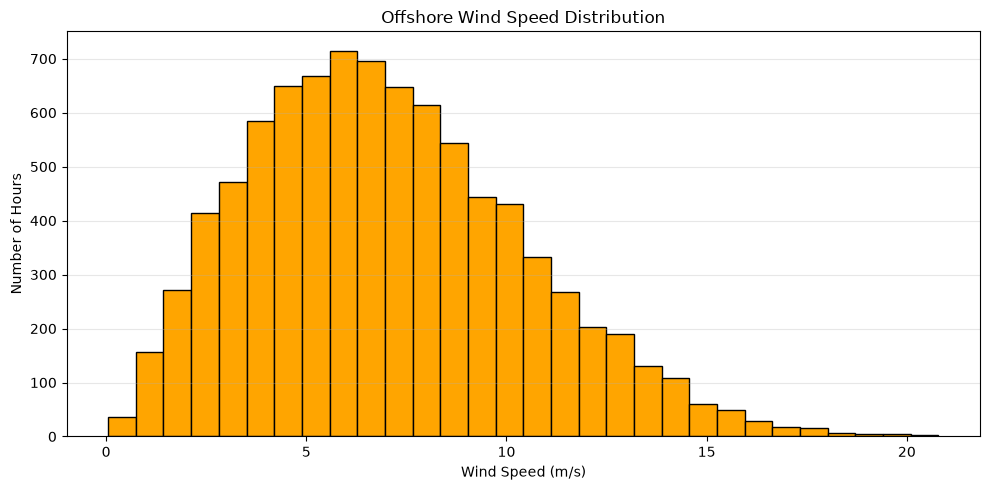

In [187]:
plt.figure(figsize=(10, 5))

plt.hist(
    wind_data["wind_speed_ms"],
    bins=30,
    color="orange", edgecolor="black"
)

plt.xlabel("Wind Speed (m/s)")
plt.ylabel("Number of Hours")
plt.title("Offshore Wind Speed Distribution")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show

In [188]:
wind_data["wind_speed_band"] = pd.cut(
    wind_data["wind_speed_ms"],
    bins=[0, 3, 5, 7, 9, 11, 13, 15, 20, 30],
    right=False
)

wind_speed_distribution = (
    wind_data["wind_speed_band"]
    .value_counts()
    .sort_index()
)
wind_speed_distribution

wind_speed_band
[0, 3)       991
[3, 5)      1690
[5, 7)      2003
[7, 9)      1755
[9, 11)     1176
[11, 13)     672
[13, 15)     330
[15, 20)     140
[20, 30)       3
Name: count, dtype: int64

In [189]:
wind_speed_percentage = (
    wind_speed_distribution / len(wind_data) * 100
)
wind_speed_percentage.round(2)

wind_speed_band
[0, 3)      11.31
[3, 5)      19.29
[5, 7)      22.87
[7, 9)      20.03
[9, 11)     13.42
[11, 13)     7.67
[13, 15)     3.77
[15, 20)     1.60
[20, 30)     0.03
Name: count, dtype: float64

In [190]:
wind_data["month"] = wind_data["timestamp"].dt.month

monthly_wind = (
    wind_data.groupby("month")["wind_speed_ms"]
    .mean()
)

monthly_wind

month
1     7.031075
2     7.112679
3     7.110484
4     7.039139
5     7.057366
6     6.940514
7     7.012137
8     7.118535
9     7.054778
10    6.989005
11    6.815444
12    6.892043
Name: wind_speed_ms, dtype: float64

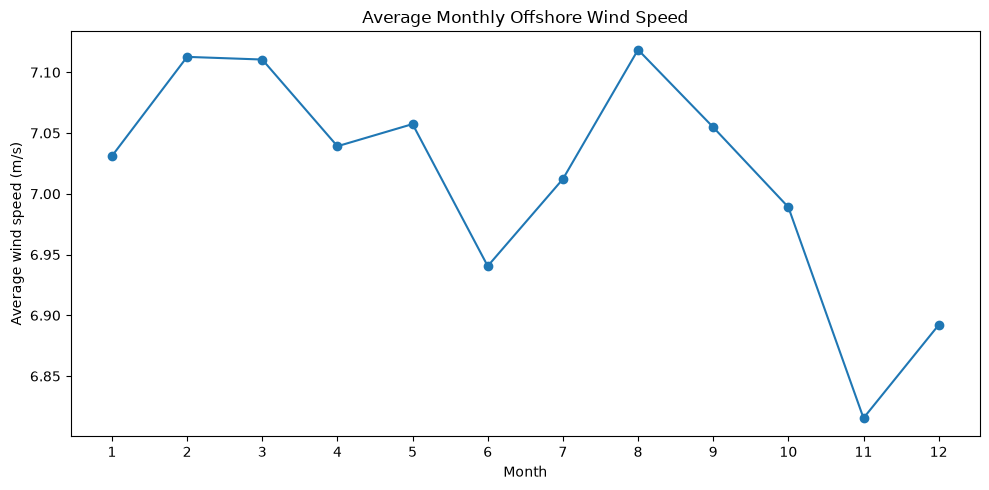

In [191]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_wind.index,
    monthly_wind.values,
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Average wind speed (m/s)")
plt.title("Average Monthly Offshore Wind Speed")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

In [192]:
rated_power_mw = 15
cut_in_speed = 3
rated_wind_speed = 12
cut_out_speed = 15

print(f"Rated power: {rated_power_mw} MW")
print(f"Cut_in wind speed: {cut_in_speed} m/s")
print(f"Rated wind speed: {rated_wind_speed} m/s")
print(f"Cut_out wind speed: {cut_out_speed}")

Rated power: 15 MW
Cut_in wind speed: 3 m/s
Rated wind speed: 12 m/s
Cut_out wind speed: 15


In [193]:
def turbine_power(wind_speed):
    if wind_speed < cut_in_speed:
        return 0

    elif wind_speed < rated_wind_speed:
        return rated_power_mw * (
            (wind_speed - cut_in_speed) / 
            (rated_wind_speed - cut_in_speed)
        ) ** 3

    elif wind_speed < cut_out_speed:
        return rated_power_mw

    else:
        return 0


        

In [194]:
test_wind_speeds = [0, 2, 3, 5, 8, 12, 15, 25, 30]

for speed in test_wind_speeds:
    power = turbine_power(speed)
    print(f"{speed} m/s - {power:.2f} MW")

0 m/s - 0.00 MW
2 m/s - 0.00 MW
3 m/s - 0.00 MW
5 m/s - 0.16 MW
8 m/s - 2.57 MW
12 m/s - 15.00 MW
15 m/s - 0.00 MW
25 m/s - 0.00 MW
30 m/s - 0.00 MW


In [195]:
wind_data["power_mw"] = (
    wind_data["wind_speed_ms"]
    .apply(turbine_power)
)

wind_data[
    ["timestamp", "wind_speed_ms", "power_mw"]
].head(10)

,timestamp,wind_speed_ms,power_mw
0,2025-01-01 00:00:00,5.67,0.391649
1,2025-01-01 01:00:00,13.20,15.000000
2,2025-01-01 02:00:00,9.07,4.601822
3,2025-01-01 03:00:00,7.68,2.109120
4,2025-01-01 04:00:00,3.57,0.003811
5,2025-01-01 05:00:00,3.57,0.003811
6,2025-01-01 06:00:00,2.22,0.000000
7,2025-01-01 07:00:00,10.99,10.495523
8,2025-01-01 08:00:00,7.70,2.136276
9,2025-01-01 09:00:00,8.79,3.993921


In [196]:
print(wind_data.columns.tolist())

['timestamp', 'wind_speed_ms', 'wind_direction_deg', 'air density_kgm3', 'temperature_c', 'wind_speed_band', 'month', 'power_mw']


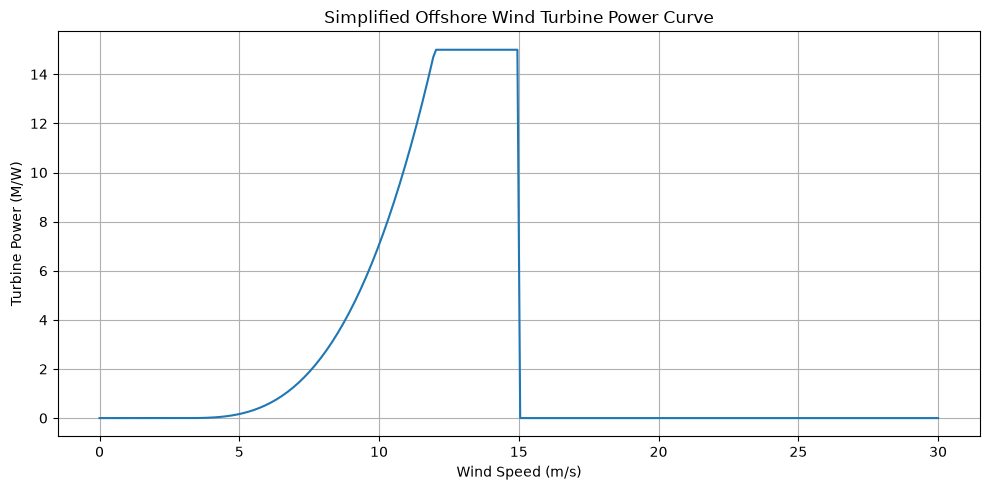

In [197]:
wind_speeds = np.linspace(0, 30, 300)

power_curve = [
    turbine_power(speed)
    for speed in wind_speeds
]
plt.figure(figsize=(10,5))
plt.plot(
     wind_speeds,
     power_curve
 )

plt.xlabel("Wind Speed (m/s)")
plt.ylabel("Turbine Power (M/W)")
plt.title("Simplified Offshore Wind Turbine Power Curve")

plt.grid(True)
plt.tight_layout()
plt.show()

In [198]:
# Calculate gross annual energy production
gross_aep_mwh = wind_data["power_mw"].sum()
print(f"Gross Annaul Energy Production: {gross_aep_mwh:,.2f} MWh")

Gross Annaul Energy Production: 28,074.68 MWh


In [199]:
#Convert to GWh
gross_aep_gwh = gross_aep_mwh / 1000
print(f"Gross Annual Energy Production: {gross_aep_gwh} GWh")

Gross Annual Energy Production: 28.074678452962967 GWh


In [200]:
# Theoretical maximum annual energy
hours_per_year = 8760
maximum_annual_energy_mwh = (
    rated_power_mw * hours_per_year
)
print(
    f"Maximum possible annual energy:"
    f"{maximum_annual_energy_mwh:,.2f} MWh"
)

Maximum possible annual energy:131,400.00 MWh


In [201]:
capacity_factor = (
    gross_aep_mwh / 
    maximum_annual_energy_mwh
)
print(f"Gross Capacity Factor: {capacity_factor:.2%}")

Gross Capacity Factor: 21.37%


In [202]:
# Calculate the equivalent full load
full_load_hours = (
    gross_aep_mwh / 
    rated_power_mw
)
print(f"Equivalent Full-load Hours: {full_load_hours:,.0f} hours")

Equivalent Full-load Hours: 1,872 hours


In [203]:
wind_data["month_name"] = wind_data["timestamp"].dt.strftime("%b")

monthly_energy = (
    wind_data
    .groupby("month_name")["power_mw"]
    .sum().round(2)
)
monthly_energy

month_name
Apr    2394.33
Aug    2403.09
Dec    2274.51
Feb    2244.86
Jan    2437.03
Jul    2388.29
Jun    2244.90
Mar    2337.85
May    2408.63
Nov    2057.50
Oct    2536.79
Sep    2346.88
Name: power_mw, dtype: float64

In [204]:
month_order = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

monthly_energy = monthly_energy.reindex(month_order)
monthly_energy

month_name
Jan    2437.03
Feb    2244.86
Mar    2337.85
Apr    2394.33
May    2408.63
Jun    2244.90
Jul    2388.29
Aug    2403.09
Sep    2346.88
Oct    2536.79
Nov    2057.50
Dec    2274.51
Name: power_mw, dtype: float64

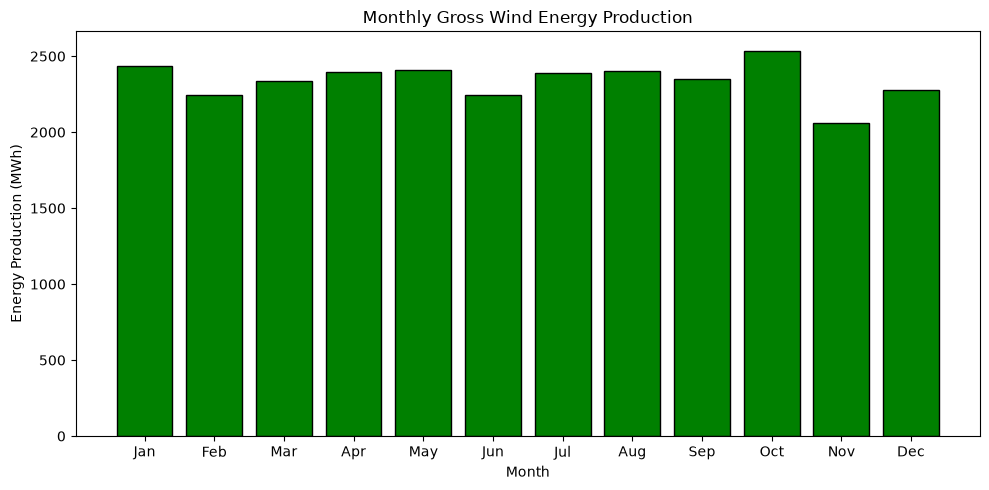

In [205]:
plt.figure(figsize=(10,5))

plt.bar(
    monthly_energy.index,
    monthly_energy.values,
    color="green", edgecolor="black"
)


plt.xlabel("Month")
plt.ylabel("Energy Production (MWh)")
plt.title("Monthly Gross Wind Energy Production")

plt.tight_layout()
plt.show()

In [206]:
# Check the hours the turbine is actually producing
generating_hours = (
    wind_data["power_mw"] > 0
).sum()

print(f"Generating Hours: {generating_hours:,}")
print(
    f"Percentage of hours generating: "
    f"{generating_hours / hours_per_year:.2%}"
)

Generating Hours: 7,621
Percentage of hours generating: 87.00%


In [207]:
# Apply energy losses

availability_loss = 5/100
wake_loss = 8/100
electrical_loss = 3/100
environmental_loss = 2/100

net_aep_mwh = gross_aep_mwh * (
    1 - availability_loss
) * (
    1 - wake_loss
) * (
    1 - electrical_loss   
)

net_aep_gwh = net_aep_mwh / 1000

print(f"Gross AEP: {gross_aep_mwh:,.2f} MWh")
print(f"Net AEP: {net_aep_gwh:,.2f} GWh")

Gross AEP: 28,074.68 MWh
Net AEP: 23.80 GWh


In [208]:
# Net capacity factor

net_capacity_factor = net_aep_mwh / maximum_annual_energy_mwh

print(f"Net AEP: {net_aep_gwh:.2f} GWh")
print(f"Net Capacity Factor: {net_capacity_factor:.2%}")

Net AEP: 23.80 GWh
Net Capacity Factor: 18.11%


In [209]:
# Net equivalent full load hours

net_full_load_hours = net_aep_mwh / rated_power_mw
print(f"Net Equivalent Full Load Hours: {net_full_load_hours:,.0f} hours")

Net Equivalent Full Load Hours: 1,587 hours


In [210]:
# Energy loss breakdown

gross = gross_aep_mwh

after_availability = gross * (1 - availability_loss)
after_wake = after_availability * (1 - wake_loss)
after_electrical = after_wake * (1 - electrical_loss)
after_environmental = after_electrical * (1 - environmental_loss)

loss_breakdown = pd.DataFrame({
    "Stage": [
        "Gross AEP",
        "After Availability",
        "After Wake Loss",
        "After Electrical Loss",
        "Net AEP"
    ],
    "Energy_MWh": [
        gross,
        after_availability,
        after_wake,
        after_electrical,
        after_environmental
    ]
})
loss_breakdown

,Stage,Energy_MWh
0,Gross AEP,28074.678453
1,After Availability,26670.944530
2,After Wake Loss,24537.268968
3,After Electrical Loss,23801.150899
4,Net AEP,23325.127881


In [211]:
# The energy impact of each loss

availability_loss_mwh = gross - after_availability
wake_loss_mwh = after_availability - after_wake
electrical_loss_mwh = after_wake - after_electrical
environmental_loss_mwh = after_electrical - after_environmental

losses = pd.DataFrame({
    "Loss Type": [
        "Availability",
        "Wake",
        "Electrical",
        "Environmental"
    ],
    "Loss_MWh": [
        availability_loss_mwh,
        wake_loss_mwh,
        electrical_loss_mwh,
        environmental_loss_mwh
    ]
})

losses["Loss_GWh"] = losses["Loss_MWh"] / 1000
losses

,Loss Type,Loss_MWh,Loss_GWh
0,Availability,1403.733923,1.403734
1,Wake,2133.675562,2.133676
2,Electrical,736.118069,0.736118
3,Environmental,476.023018,0.476023


In [212]:
#Final net energy metrics after all losses

net_aep_mwh = after_environmental
net_aep_gwh = net_aep_mwh / 1000

net_capacity_factor = (
    net_aep_mwh / maximum_annual_energy_mwh
)

net_full_load_hours = (
    net_aep_mwh / rated_power_mw
)

print(f"Gross AEP: {gross_aep_mwh:,.2f} MWh")
print(f"Net AEP: {net_aep_gwh:,.2f} GWh")
print(f"Net Capacity Factor: {net_capacity_factor:.2%}")
print(f"Net Equivalent Full load Hours: {net_full_load_hours:,.0f} hours")

Gross AEP: 28,074.68 MWh
Net AEP: 23.33 GWh
Net Capacity Factor: 17.75%
Net Equivalent Full load Hours: 1,555 hours


In [213]:
#CAPEX and OPEX assumption

project_capacity_mw = 15

capex_per_mw = 3_500_000
total_capex = project_capacity_mw * capex_per_mw

annual_opex_per_mw = 100_000
annual_opex = project_capacity_mw * annual_opex_per_mw

print(f"Project capacity: {project_capacity_mw} MW")
print(f"CAPEX assumption: £{capex_per_mw:,.0f} per MW")
print(f"Total CAPEX: £{total_capex:,.0f}")
print(f"OPEX assumption: £{annual_opex_per_mw:,.0f} per MW/year")
print(f"Annual OPEX: £{annual_opex:,.0f}")

Project capacity: 15 MW
CAPEX assumption: £3,500,000 per MW
Total CAPEX: £52,500,000
OPEX assumption: £100,000 per MW/year
Annual OPEX: £1,500,000


In [214]:
# LCOE model assumptions
project_lifetime_years = 25
discount_rate = 0.08
print(f"Project Lifetime: {project_lifetime_years} years")
print(f"Discount Rate: {discount_rate:,.1%}")
print(f"Total CAPEX: {total_capex:,.0f}")
print(f"Annual OPEX: {annual_opex:,.0f}")
print(f"Net Annual Energy: {net_aep_mwh:,.2f} MWh")

Project Lifetime: 25 years
Discount Rate: 8.0%
Total CAPEX: 52,500,000
Annual OPEX: 1,500,000
Net Annual Energy: 23,325.13 MWh


In [215]:
# Project lifetime timeline
years = np.arange(1, project_lifetime_years + 1)

lcoe_model = pd.DataFrame({
    "Year": years
})

lcoe_model.head()

,Year
0,1
1,2
2,3
3,4
4,5


In [216]:
# Energy production and operation cost
lcoe_model["Energy_MWh"] = net_aep_mwh
lcoe_model["OPEX"] = annual_opex

lcoe_model.head()

,Year,Energy_MWh,OPEX
0,1,23325.127881,1500000
1,2,23325.127881,1500000
2,3,23325.127881,1500000
3,4,23325.127881,1500000
4,5,23325.127881,1500000


In [217]:
# Discount factor for each year

lcoe_model["Discount Factor"] = (
    1 / ((1 + discount_rate) ** lcoe_model["Year"])
)

lcoe_model.head()

,Year,Energy_MWh,OPEX,Discount Factor
0,1,23325.127881,1500000,0.925926
1,2,23325.127881,1500000,0.857339
2,3,23325.127881,1500000,0.793832
3,4,23325.127881,1500000,0.735030
4,5,23325.127881,1500000,0.680583


In [218]:
# Discounted energy and discounted OPEX

lcoe_model["Discounted_Energy_MWh"] = (
    lcoe_model["Energy_MWh"] * 
    lcoe_model["Discount Factor"]
)

lcoe_model["Discounted_OPEX"] = (
    lcoe_model["OPEX"] * 
    lcoe_model["Discount Factor"]
)

lcoe_model.head()

,Year,Energy_MWh,OPEX,Discount Factor,Discounted_Energy_MWh,Discounted_OPEX
0,1,23325.127881,1500000,0.925926,21597.340630,1.388889e+06
1,2,23325.127881,1500000,0.857339,19997.537621,1.286008e+06
2,3,23325.127881,1500000,0.793832,18516.238538,1.190748e+06
3,4,23325.127881,1500000,0.735030,17144.665313,1.102545e+06
4,5,23325.127881,1500000,0.680583,15874.690104,1.020875e+06


In [219]:
# Total discounted energy and OPEX

total_discounted_energy = lcoe_model["Discounted_Energy_MWh"].sum()
total_discounted_opex = lcoe_model["Discounted_OPEX"].sum()

print(f"Total discounted energy: {total_discounted_energy:,.2f} MWh")
print(f"Toatal discounted OPEX: £{total_discounted_opex:,.2f}")

Total discounted energy: 248,990.52 MWh
Toatal discounted OPEX: £16,012,164.28


In [220]:
total_discounted_cost = (
    total_capex + total_discounted_opex
)

lcoe = (
    total_discounted_cost / 
    total_discounted_energy
)

print(f"Total discounted cost: £{total_discounted_cost:,.2f}")
print(f"LCOE: £{lcoe:,.2f}/MWh")

Total discounted cost: £68,512,164.28
LCOE: £275.16/MWh


In [221]:
# CAPEX sensitivity analysis

capex_per_mw_values = np.array([
    2.5,
    3.0,
    3.5,
    4.0,
    4.5
])

capex_sensitivity = pd.DataFrame({
    "CAPEX_per_MW_million": capex_per_mw_values
})

capex_sensitivity

,CAPEX_per_MW_million
0,2.5
1,3.0
2,3.5
3,4.0
4,4.5


In [222]:
# Total CAPEX for each scenerio

capex_sensitivity["Total_CAPEX"] = (
    capex_sensitivity["CAPEX_per_MW_million"] * 
    project_capacity_mw
) * 1_000_000

# LCOE for each CAPEXscenerio

capex_sensitivity["LCOE_per_MWh"] = (
    capex_sensitivity["Total_CAPEX"] + 
    total_discounted_opex
) / total_discounted_energy

capex_sensitivity

,CAPEX_per_MW_million,Total_CAPEX,LCOE_per_MWh
0,2.5,37500000.0,214.916473
1,3.0,45000000.0,245.038102
2,3.5,52500000.0,275.159730
3,4.0,60000000.0,305.281359
4,4.5,67500000.0,335.402988


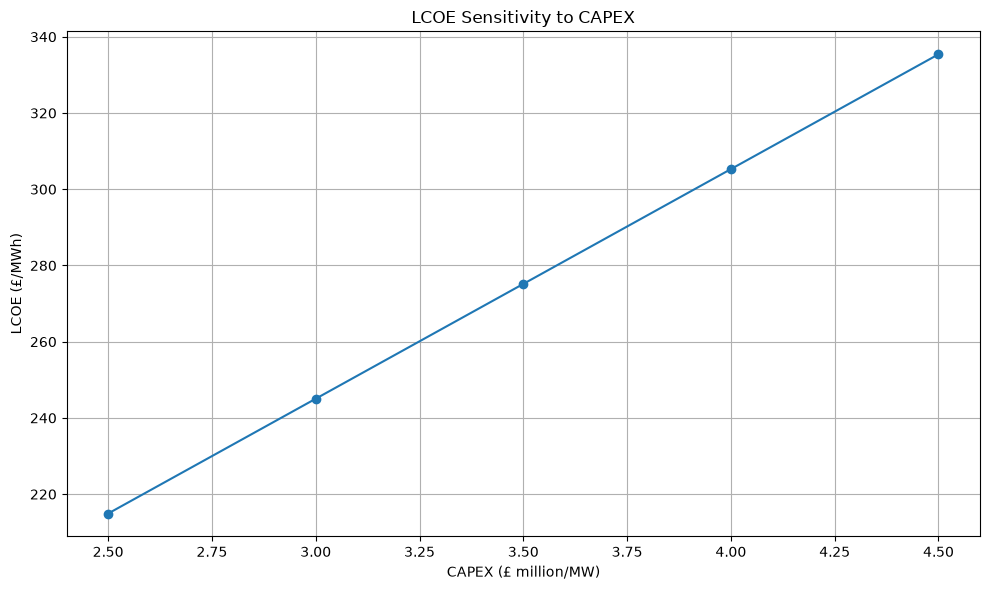

In [223]:
#Plot CAPEX sensitivity 

plt.figure(figsize=(10,6))

plt.plot(
    capex_sensitivity["CAPEX_per_MW_million"],
    capex_sensitivity["LCOE_per_MWh"],
    marker="o"
)
plt.xlabel("CAPEX (£ million/MW)")
plt.ylabel("LCOE (£/MWh)")
plt.title("LCOE Sensitivity to CAPEX")
plt.grid(True)
plt.tight_layout()
plt.show()

In [224]:
# OPEX sensitivity analysis

annual_opex_values = np.array([
    1.0,
    1.25,
    1.5,
    1.75,
    2.0
])
opex_sensitivity = pd.DataFrame({
    "Annual_OPEX_million": annual_opex_values
})
opex_sensitivity

,Annual_OPEX_million
0,1.00
1,1.25
2,1.50
3,1.75
4,2.00


In [225]:
opex_sensitivity["Total_Discounted_OPEX"] = (
    opex_sensitivity["Annual_OPEX_million"] * 1_000_000
    *((1 - (1 + discount_rate) ** -project_lifetime_years) / discount_rate)
)

opex_sensitivity["Total_Discounted_Cost"] = (
    total_capex + opex_sensitivity["Total_Discounted_OPEX"]
)

opex_sensitivity["LCOE"] = (
    opex_sensitivity["Total_Discounted_Cost"] / total_discounted_energy
)

opex_sensitivity

,Annual_OPEX_million,Total_Discounted_OPEX,Total_Discounted_Cost,LCOE
0,1.00,1.067478e+07,6.317478e+07,253.723621
1,1.25,1.334347e+07,6.584347e+07,264.441676
2,1.50,1.601216e+07,6.851216e+07,275.159730
3,1.75,1.868086e+07,7.118086e+07,285.877785
4,2.00,2.134955e+07,7.384955e+07,296.595840


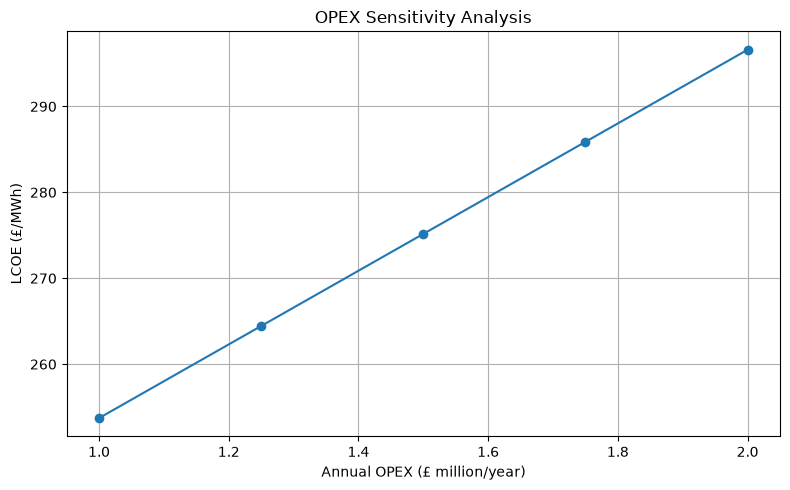

In [226]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.plot(
    opex_sensitivity["Annual_OPEX_million"],
    opex_sensitivity["LCOE"],
    marker="o"
)

plt.xlabel("Annual OPEX (£ million/year)")
plt.ylabel("LCOE (£/MWh)")
plt.title("OPEX Sensitivity Analysis")
plt.grid(True)
plt.tight_layout()
plt.show()